In [3]:
!pip install -q roboflow ultralytics huggingface_hub

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


# Download Dataset Roboflow

In [4]:
import os
import json
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from PIL import Image
from roboflow import Roboflow
from datetime import datetime
from huggingface_hub import hf_hub_download
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [5]:
API_KEY = "B6wvsNgQ7tcG9XoIQLN4"

rf = Roboflow(api_key=API_KEY)
project = rf.workspace("mostafa-ali-fdvdb").project("road-damage-l1ju7-zqw9l")
version = project.version(1)
dataset = version.download("yolov8" , location="dataset")

print("Completed Succesfully" , dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to dataset in yolov8:: 100%|██████████| 13518/13518 [00:03<00:00, 3829.13it/s]


Completed Succesfully /kaggle/working/dataset


# Paths

In [6]:
DATA_YAML          = "/kaggle/working/dataset/data.yaml"       
EXPERIMENTS_DIR    = "/kaggle/working/experiments"        
OUTPUTS_DIR        = "/kaggle/working/outputs"
RESULTS_JSON       = "/kaggle/working/outputs/results.json"  
PLOTS_DIR          = "/kaggle/working/outputs/plots"           
VAL_IMAGES_DIR     = "/kaggle/working/dataset/valid/images"    
VAL_LABELS_DIR     = "/kaggle/working/dataset/valid/labels"    
PREDICTIONS_DIR    = "/kaggle/working/outputs/predictions"   
IOU_THRESHOLD      = 0.5    
NUM_IMAGES_TO_SHOW = 9 

# Models

In [8]:
MODELS = ["yolov8n.pt", "yolov8s.pt", "yolov8m.pt"]

# Hyperprameters

In [10]:
EPOCHS = 60
BATCH_SIZE = 16
IMAGE_SIZE = 640
LEARNING_RATE = 0.01
OPTIMIZER = "auto"      # SGD / Adam / AdamW / auto
SEED = 42

In [12]:
def train_one_model(weights_name: str) -> dict:
    # to save the model name only
    model_name = weights_name.replace(".pt" , "")
    # to save each experiment model and time start 
    run_name = f"{model_name}_{datetime.now().strftime('%Y%m%d_%H%M%S')}"
    
    print(f"\n=== Start training {model_name} ===")
    # Call The Model And Train
    model = YOLO(weights_name)
    model.train(
        
        data = DATA_YAML,
        epochs = EPOCHS,
        batch = BATCH_SIZE,
        imgsz = IMAGE_SIZE,
        lr0 = LEARNING_RATE,
        optimizer = OPTIMIZER,
        seed=SEED,
        project=EXPERIMENTS_DIR,
        name=run_name,  
    )

    # save the best model to best model path
    best_model_path = os.path.join(EXPERIMENTS_DIR , run_name ,"weights", "best.pt")
    if not os.path.exists(best_model_path):
        raise FileNotFoundError(
            f"Best weights were not created: {best_model_path}"
        )
        
    best_model = YOLO(best_model_path)
    
    # Model Evaluation
    metrics = best_model.val(data=DATA_YAML)
    map50 = metrics.box.map50
    map50_95 = metrics.box.map
    precision = metrics.box.mp
    recall = metrics.box.mr


    # calcualte model size and speed of prediction per image
    model_size_mb = os.path.getsize(best_model_path) / (1024 * 1024)
    dummy_images = "/kaggle/working/dataset/valid/images"
    sample_images = os.listdir(dummy_images) if os.path.exists(dummy_images) else []

    fps = None
    avg_inference_ms = None
    
    if sample_images:
        sample_path = os.path.join(dummy_images , sample_images[0])
        #just_test_one_pic
        best_model.predict(sample_path , verbose = False)
        start = time.time()
        n_runs = 20
        for _ in range (n_runs):
            best_model.predict(sample_path , verbose = False)
        elapsed = time.time() - start
        avg_inference_ms = (elapsed / n_runs) * 1000
        fps = 1000 / avg_inference_ms
        
    result = {
        "model_name": model_name,
        "best_weights_path": best_model_path,
        "mAP50": round(map50, 4),
        "mAP50-95": round(map50_95, 4),
        "precision": round(precision, 4),
        "recall": round(recall, 4),
        "model_size_mb": round(model_size_mb, 2),
        "avg_inference_ms": round(avg_inference_ms, 2) if avg_inference_ms else None,
        "fps": round(fps, 2) if fps else None,
    }

    print(f"model name: {model_name} | best weights path: {best_model_path}")
    print(
        f"mAP50={result['mAP50']} | mAP50-95={result['mAP50-95']} | "
        f"Precision={result['precision']} | Recall={result['recall']} | "
        f"Size={result['model_size_mb']} MB | FPS={result['fps']}"
    )
    return result

In [13]:
def train_all_models():
    results = []
    for weights_name in MODELS:
        try:
            result = train_one_model(weights_name)
            results.append(result)
            # Save results after every successful model
            save_results(results)
            print(f"\n{weights_name} completed and results saved.")
        except Exception as e:
            print(f"\nError while training {weights_name}: {e}")
            print("Previous completed models are preserved.")
            raise
    return results

In [14]:
def print_comparison_table(results: list):

    if not results:
        print("No results available.")
        return
    
    print("\n=== Comparison Table ===")
    header = f"{'Model':<10}{'mAP50':<10}{'mAP50-95':<12}{'Precision':<12}{'Recall':<10}{'Size(MB)':<10}{'FPS':<10}"
    print(header)
    print("-" * len(header))
    for r in results:
        print(
            f"{r['model_name']:<10}{r['mAP50']:<10}{r['mAP50-95']:<12}"
            f"{r['precision']:<12}{r['recall']:<10}{r['model_size_mb']:<10}{r['fps']:<10}"
        )
    best = max(results, key=lambda r: r["mAP50-95"])
    print(f"\nBest model for deployment (highest mAP50-95): {best['model_name']}")
    print(f"Weights path: {best['best_weights_path']}")

In [16]:
def save_results(results: list):
    os.makedirs(os.path.dirname(RESULTS_JSON), exist_ok=True)

    with open(RESULTS_JSON, "w", encoding="utf-8") as f:
        json.dump(results, f, indent=2, ensure_ascii=False)

    print(f"\nsaved result: {RESULTS_JSON}")

In [17]:
all_results = train_all_models()
print_comparison_table(all_results)
save_results(all_results)


=== Start training yolov8n ===
Ultralytics 8.4.208 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_20261110_150819

`get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.


       2/60      2.94G      1.915      2.493      1.828         65        640: 100% ━━━━━━━━━━━━ 308/308 5.3it/s 57.9s0.4ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.6it/s 9.9s0.2s
                   all       1142       3570      0.288      0.145      0.134     0.0514

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/60      2.95G        1.9      2.437      1.816         85        640: 100% ━━━━━━━━━━━━ 308/308 5.3it/s 58.5s0.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 36/36 3.7it/s 9.8s0.2s
                   all       1142       3570       0.28      0.175      0.168     0.0828

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/60      2.95G      1.878      2.368      1.797         81        640: 100% ━━━━━━━━━━━━ 308/308 5.4it/s 57.0s0.3ss
                 Class     Ima

# Evaluate Models

In [19]:
def load_results() -> list:
    if not os.path.exists(RESULTS_JSON):
        raise FileNotFoundError(
            f"No Found File '{RESULTS_JSON}'. "
        )
    with open(RESULTS_JSON, "r", encoding="utf-8") as f:
        return json.load(f)

In [20]:
def print_comparison_table(results: list):
    print("\n=== Comparison Table ===")
    header = f"{'Model':<10}{'mAP50':<10}{'mAP50-95':<12}{'Precision':<12}{'Recall':<10}{'Size(MB)':<10}{'FPS':<10}"
    print(header)
    print("-" * len(header))
    for r in results:
        print(
            f"{r['model_name']:<10}{r['mAP50']:<10}{r['mAP50-95']:<12}"
            f"{r['precision']:<12}{r['recall']:<10}{r['model_size_mb']:<10}{r['fps']:<10}"
        )
    best = max(results, key=lambda r: r["mAP50-95"])
    print(f"\nBest model (highest mAP50-95): {best['model_name']}")

In [21]:
def _bar_plot(results: list, metric_key: str, title: str, ylabel: str, filename: str):
    names = [r["model_name"] for r in results]
    values = [r[metric_key] for r in results]
 
    plt.figure(figsize=(6, 4))
    bars = plt.bar(names, values, color=["#4C72B0", "#55A868", "#C44E52"])
    plt.title(title)
    plt.ylabel(ylabel)
    plt.xlabel("Model")
    for bar, value in zip(bars, values):
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            str(value),
            ha="center",
            va="bottom",
        )
 
    plt.tight_layout()
    os.makedirs(PLOTS_DIR, exist_ok=True)
    save_path = os.path.join(PLOTS_DIR, filename)
    plt.savefig(save_path)
    plt.close()
    print(f"Saved Plots: {save_path}")

In [22]:
def plot_all_comparisons(results: list):
    _bar_plot(results, "mAP50", "mAP50 Comparison", "mAP50", "map50.png")
    _bar_plot(results, "mAP50-95", "mAP50-95 Comparison", "mAP50-95", "map50_95.png")
    _bar_plot(results, "precision", "Precision Comparison", "Precision", "precision.png")
    _bar_plot(results, "recall", "Recall Comparison", "Recall", "recall.png")
    _bar_plot(results, "model_size_mb", "Model Size Comparison", "Size (MB)", "model_size.png")
    _bar_plot(results, "fps", "Inference Speed (FPS) Comparison", "FPS", "fps.png")

In [23]:
all_results = load_results()
print_comparison_table(all_results)
plot_all_comparisons(all_results) 


=== Comparison Table ===
Model     mAP50     mAP50-95    Precision   Recall    Size(MB)  FPS       
--------------------------------------------------------------------------
yolov8n   0.4169    0.2457      0.602       0.3987    6.2       95.19     
yolov8s   0.4301    0.2473      0.4679      0.4272    21.47     64.0      
yolov8m   0.4249    0.2428      0.4736      0.4395    49.62     36.9      

Best model (highest mAP50-95): yolov8s
Saved Plots: /kaggle/working/outputs/plots/map50.png
Saved Plots: /kaggle/working/outputs/plots/map50_95.png
Saved Plots: /kaggle/working/outputs/plots/precision.png
Saved Plots: /kaggle/working/outputs/plots/recall.png
Saved Plots: /kaggle/working/outputs/plots/model_size.png
Saved Plots: /kaggle/working/outputs/plots/fps.png


# Visualize

In [24]:
def get_best_model_path() -> str:
    if not os.path.exists(RESULTS_JSON):
        raise FileNotFoundError(
            f"No result in file '{RESULTS_JSON}'"
        )
    with open(RESULTS_JSON, "r", encoding="utf-8") as f:
        results = json.load(f)
    best = max(results, key=lambda r: r["mAP50-95"])
    print(f"Best Model {best['model_name']} ({best['best_weights_path']})")
    return best["best_weights_path"]

In [25]:
def load_ground_truth(label_path: str, img_width: int, img_height: int) -> list:
    boxes = []
    if not os.path.exists(label_path):
        return boxes
 
    with open(label_path, "r") as f:
        for line in f.readlines():
            parts = line.strip().split()
            if len(parts) != 5:
                continue
            class_id, xc, yc, w, h = map(float, parts)
            x1 = (xc - w / 2) * img_width
            y1 = (yc - h / 2) * img_height
            x2 = (xc + w / 2) * img_width
            y2 = (yc + h / 2) * img_height
            boxes.append([int(class_id), x1, y1, x2, y2])
    return boxes

In [26]:
def compute_iou(box1: list, box2: list) -> float:
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])
 
    inter_area = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union_area = area1 + area2 - inter_area
 
    return inter_area / union_area if union_area > 0 else 0.0

In [27]:
def match_predictions_to_ground_truth(predictions: list, ground_truths: list) -> list:
    used_gt = set()
    evaluated = []
 
    for pred in predictions:
        pred_class, px1, py1, px2, py2, conf = pred
        best_iou = 0.0
        best_gt_idx = -1
 
        for idx, gt in enumerate(ground_truths):
            if idx in used_gt or gt[0] != pred_class:
                continue
            iou = compute_iou([px1, py1, px2, py2], gt[1:])
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = idx
 
        is_correct = best_iou >= IOU_THRESHOLD
        if is_correct:
            used_gt.add(best_gt_idx)
 
        evaluated.append(
            {
                "class_id": pred_class,
                "box": [px1, py1, px2, py2],
                "confidence": conf,
                "iou": round(best_iou, 2),
                "correct": is_correct,
            }
        )
 
    return evaluated

In [28]:
def draw_image_with_predictions(ax, image_path: str, evaluated_predictions: list, class_names: dict):
    image = Image.open(image_path)
    ax.imshow(image)
    ax.axis("off")
 
    for pred in evaluated_predictions:
        x1, y1, x2, y2 = pred["box"]
        color = "lime" if pred["correct"] else "red"
        label = f"{class_names.get(pred['class_id'], pred['class_id'])} {pred['confidence']:.2f}"
 
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=2, edgecolor=color, facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(
            x1, max(y1 - 5, 0), label,
            color="white", fontsize=7,
            bbox=dict(facecolor=color, alpha=0.7, pad=1),
        )
 
    n_correct = sum(1 for p in evaluated_predictions if p["correct"])
    n_total = len(evaluated_predictions)
    ax.set_title(f"{n_correct}/{n_total} correct", fontsize=9)

In [29]:
def visualize():
    model_path = get_best_model_path()
    model = YOLO(model_path)
    class_names = model.names  # dict: {0: "car", 1: "truck", ...}
 
    all_images = [f for f in os.listdir(VAL_IMAGES_DIR) if f.lower().endswith((".jpg", ".png", ".jpeg"))]
    if not all_images:
        raise FileNotFoundError(f"Not Found image : '{VAL_IMAGES_DIR}'")
 
    sample_images = random.sample(all_images, min(NUM_IMAGES_TO_SHOW, len(all_images)))
 
    os.makedirs(PREDICTIONS_DIR, exist_ok=True)
 
    total_correct = 0
    total_wrong = 0
 
    grid_size = int(NUM_IMAGES_TO_SHOW ** 0.5) or 1
    fig, axes = plt.subplots(grid_size, grid_size, figsize=(4 * grid_size, 4 * grid_size))
    axes = axes.flatten() if NUM_IMAGES_TO_SHOW > 1 else [axes]
 
    for i, image_name in enumerate(sample_images):
        image_path = os.path.join(VAL_IMAGES_DIR, image_name)
        label_path = os.path.join(VAL_LABELS_DIR, os.path.splitext(image_name)[0] + ".txt")
 
        with Image.open(image_path) as img:
            img_width, img_height = img.size

        results = model.predict(image_path, verbose=False)[0]
        predictions = [
            [int(cls), *box, conf]
            for box, cls, conf in zip(
                results.boxes.xyxy.tolist(),
                results.boxes.cls.tolist(),
                results.boxes.conf.tolist(),
            )
        ]
 
        ground_truths = load_ground_truth(label_path, img_width, img_height)
        evaluated = match_predictions_to_ground_truth(predictions, ground_truths)
        total_correct += sum(1 for p in evaluated if p["correct"])
        total_wrong += sum(1 for p in evaluated if not p["correct"])
 
        draw_image_with_predictions(axes[i], image_path, evaluated, class_names)
    for j in range(len(sample_images), len(axes)):
        axes[j].axis("off")
 
    plt.tight_layout()
    grid_path = os.path.join(PREDICTIONS_DIR, "predictions_grid.png")
    plt.savefig(grid_path, dpi=150)
    plt.show()
    print(f"\nsave in gride: {grid_path}")
 
    print(f"Number of correct   : {total_correct}")
    print(f"Number of incorrect: {total_wrong}")
    total = total_correct + total_wrong
    if total > 0:
        print(f"confidence : {total_correct / total * 100:.1f}%")

Best Model yolov8s (/kaggle/working/experiments/yolov8s_20261110_161614/weights/best.pt)


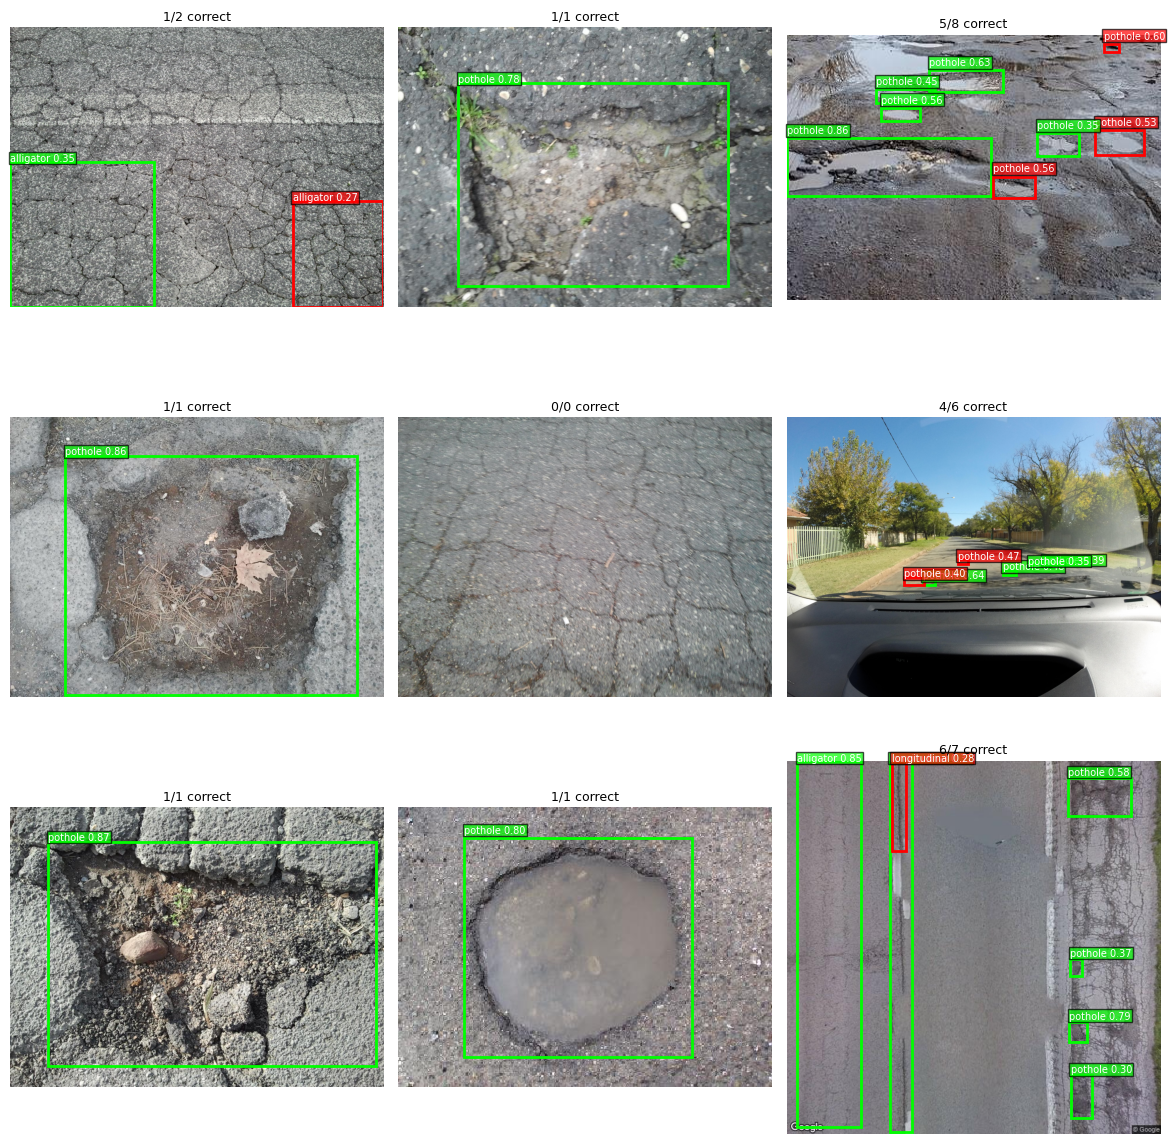


save in gride: /kaggle/working/outputs/predictions/predictions_grid.png
Number of correct   : 20
Number of incorrect: 7
confidence : 74.1%


In [30]:
 visualize()

In [32]:

import os
import zipfile
from IPython.display import FileLink, display

SOURCE_DIR = "/kaggle/working"
ZIP_PATH = "/kaggle/working/full_backup.zip"

EXCLUDE_DIRS = {"dataset", ".virtual_documents"}

print("Creating backup without dataset...")

with zipfile.ZipFile(
    ZIP_PATH, "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=1
) as zipf:

    for root, dirs, files in os.walk(SOURCE_DIR):
        dirs[:] = [
            d for d in dirs
            if d not in EXCLUDE_DIRS
        ]

        for file in files:
            file_path = os.path.join(root, file)

            if file_path == ZIP_PATH:
                continue

            arcname = os.path.relpath(file_path, SOURCE_DIR)
            zipf.write(file_path, arcname)

print("Backup completed!")
print(f"Size: {os.path.getsize(ZIP_PATH) / (1024**3):.2f} GB")

display(FileLink(ZIP_PATH))


Creating backup without dataset...
Backup completed!
Size: 0.25 GB


/kaggle/working/full_backup.zip